In [7]:
from google.colab import files

uploaded = files.upload()

Saving GUNGUN_BIT & GUNGUN_KUMARI_NAME.wav to GUNGUN_BIT & GUNGUN_KUMARI_NAME.wav


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

In [9]:
filename = list(uploaded.keys())[0]

audio, sr = librosa.load(filename, sr=None, mono=True)

duration = len(audio) / sr

print("File name:", filename)
print("Sampling Frequency:", sr, "Hz")
print("Number of Samples:", len(audio))
print("Duration:", round(duration, 3), "seconds")

File name: GUNGUN_BIT & GUNGUN_KUMARI_NAME.wav
Sampling Frequency: 16000 Hz
Number of Samples: 64512
Duration: 4.032 seconds


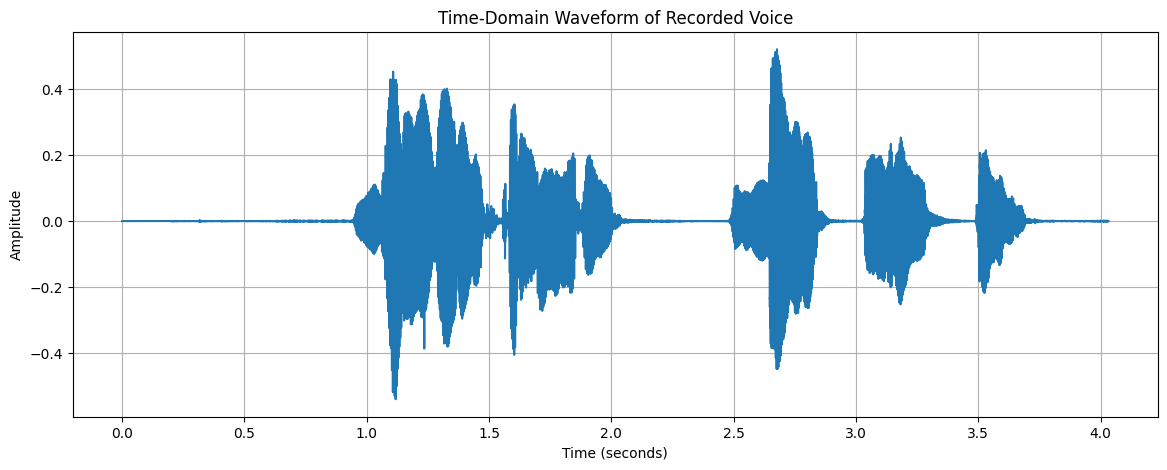

In [10]:
time = np.arange(len(audio)) / sr

plt.figure(figsize=(14, 5))

plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Time-Domain Waveform of Recorded Voice")
plt.grid(True)

plt.show()

In [11]:
# Detect non-silent portions
intervals = librosa.effects.split(
    audio,
    top_db=35,
    frame_length=2048,
    hop_length=512
)

print("Non-silent intervals:")

for start, end in intervals:
    print(
        f"{start/sr:.3f} s  to  {end/sr:.3f} s"
    )

Non-silent intervals:
0.896 s  to  2.112 s
2.432 s  to  2.944 s
2.976 s  to  3.424 s
3.456 s  to  3.776 s


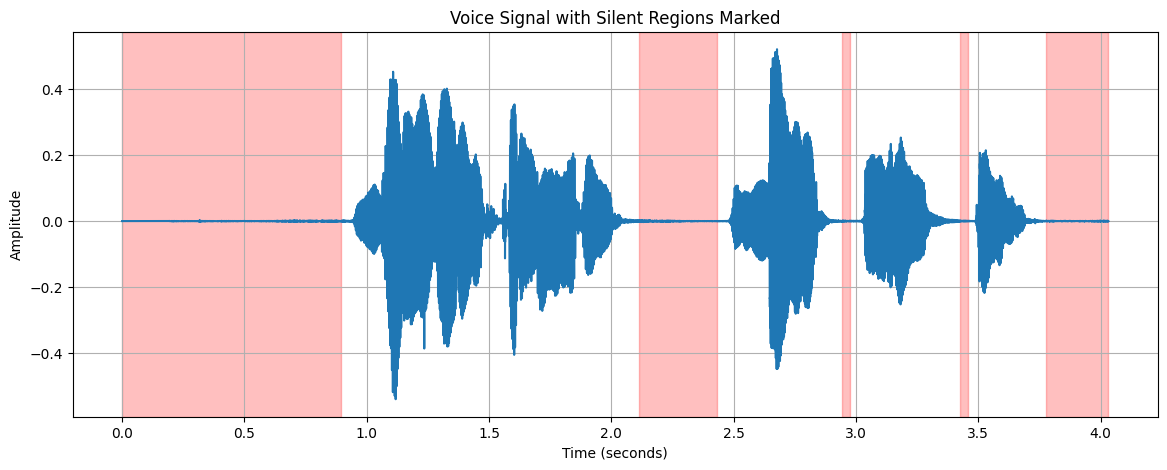

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(time, audio, label="Voice Signal")

# Start of the first non-silent region
current_end = 0

for start, end in intervals:

    # Mark silence before the current speech region
    if start > current_end:
        plt.axvspan(
            current_end / sr,
            start / sr,
            color='red',
            alpha=0.25
        )

    current_end = end

# Mark silence after the last speech region
if current_end < len(audio):
    plt.axvspan(
        current_end / sr,
        len(audio) / sr,
        color='red',
        alpha=0.25
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Voice Signal with Silent Regions Marked")

plt.grid(True)

plt.show()

In [13]:
speech_parts = []

for start, end in intervals:
    speech_parts.append(audio[start:end])

processed_audio = np.concatenate(speech_parts)

processed_duration = len(processed_audio) / sr

print("Original duration:",
      round(len(audio) / sr, 3), "seconds")

print("Processed duration:",
      round(processed_duration, 3), "seconds")

Original duration: 4.032 seconds
Processed duration: 2.496 seconds


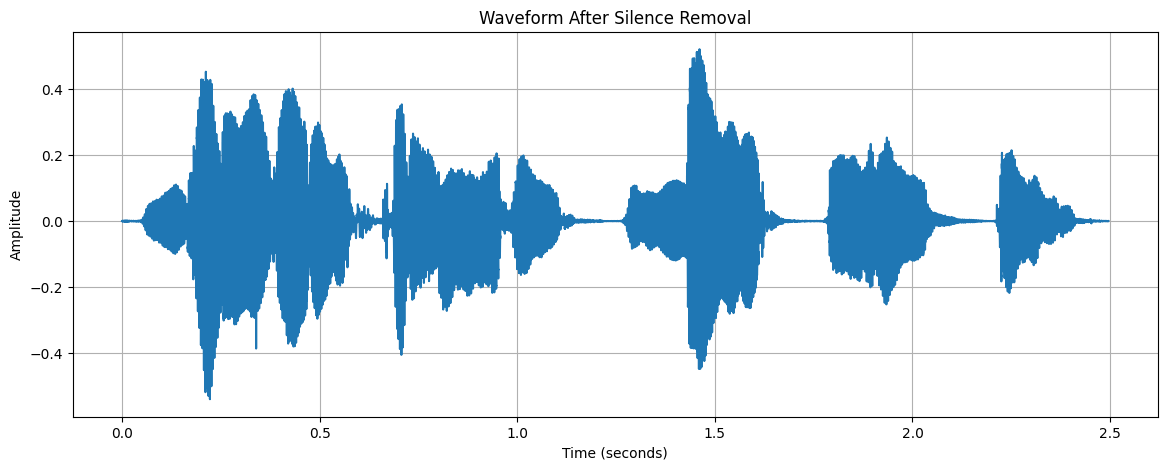

In [14]:
processed_time = np.arange(len(processed_audio)) / sr

plt.figure(figsize=(14, 5))

plt.plot(processed_time, processed_audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform After Silence Removal")

plt.grid(True)

plt.show()

In [15]:
output_filename = "GUNGUN_BIT_NAME_processed.wav"

sf.write(
    output_filename,
    processed_audio,
    sr
)

print("Processed audio saved as:", output_filename)

Processed audio saved as: GUNGUN_BIT_NAME_processed.wav


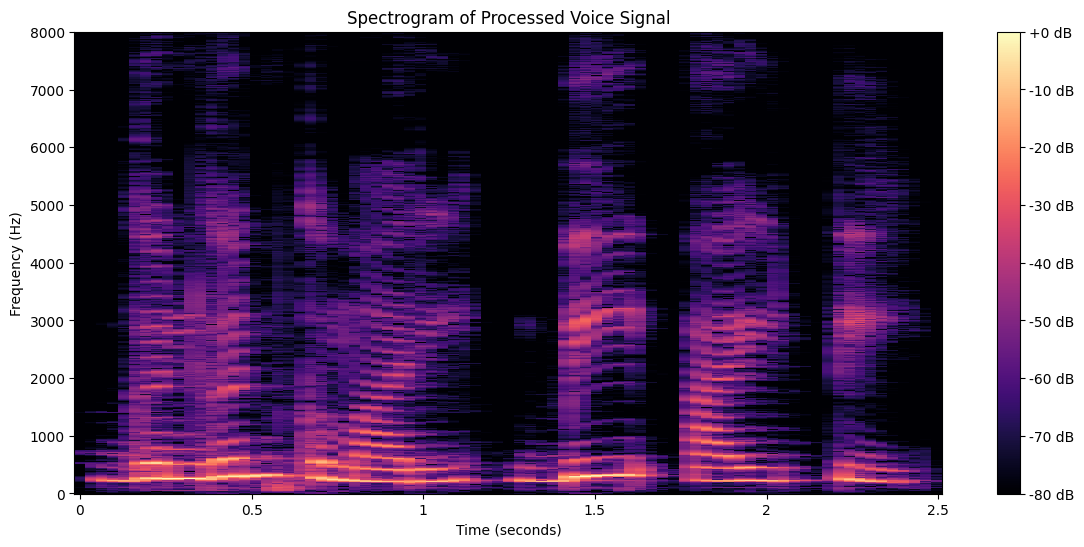

In [16]:
plt.figure(figsize=(14, 6))

D = librosa.stft(processed_audio)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis='time',
    y_axis='hz'
)

plt.colorbar(format='%+2.0f dB')

plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram of Processed Voice Signal")

plt.show()

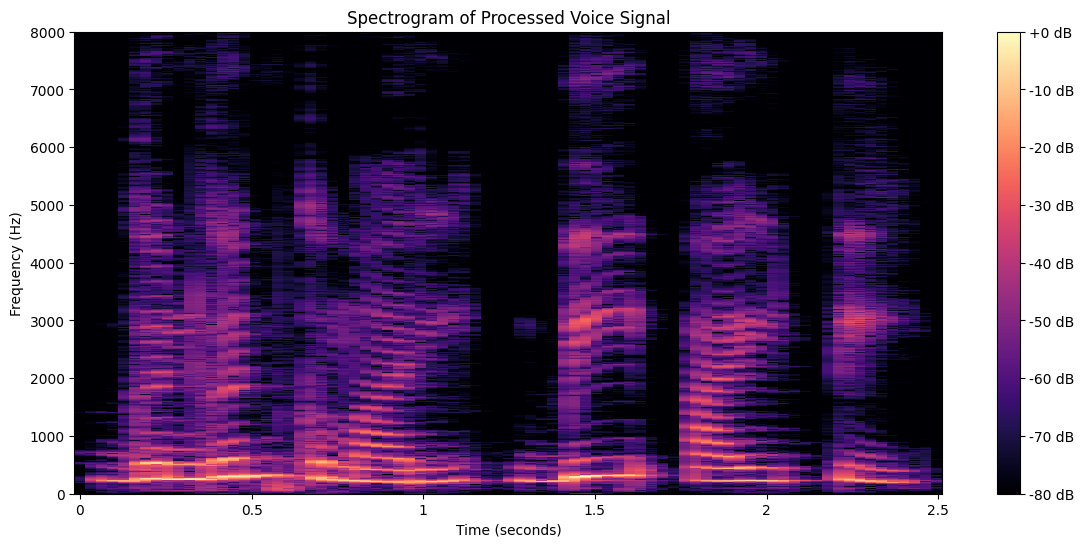

In [17]:
plt.figure(figsize=(14, 6))

D = librosa.stft(processed_audio)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis='time',
    y_axis='hz',
    cmap='magma'
)

plt.ylim(0, 8000)

plt.colorbar(format='%+2.0f dB')

plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram of Processed Voice Signal")

plt.show()

In [18]:
files.download(output_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>